In [2]:
# Step -1 Import libraries.
import pandas as pd 
import matplotlib.pyplot as plt

# Load Data 
df = pd.read_csv("netflix_titles.csv")


# Show all columns
pd.set_option("display.max_columns", None)

# Set the maximum width of the displayed table
pd.set_option("display.width", 200)

# Show the first 10 rows
display(df.head(10))



,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...
5,80163890,TV Show,Apaches,NaN,"Alberto Ammann, Eloy Azorín, Verónica Echegui,...",Spain,"September 8, 2017",2016,TV-MA,1 Season,"Crime TV Shows, International TV Shows, Spanis...",A young journalist is forced into a life of cr...
6,70304989,Movie,Automata,Gabe Ibáñez,"Antonio Banderas, Dylan McDermott, Melanie Gri...","Bulgaria, United States, Spain, Canada","September 8, 2017",2014,R,110 min,"International Movies, Sci-Fi & Fantasy, Thrillers","In a dystopian future, an insurance adjuster f..."
7,80164077,Movie,Fabrizio Copano: Solo pienso en mi,"Rodrigo Toro, Francisco Schultz",Fabrizio Copano,Chile,"September 8, 2017",2017,TV-MA,60 min,Stand-Up Comedy,Fabrizio Copano takes audience participation t...
8,80117902,TV Show,Fire Chasers,NaN,NaN,United States,"September 8, 2017",2017,TV-MA,1 Season,"Docuseries, Science & Nature TV","As California's 2016 fire season rages, brave ..."
9,70304990,Movie,Good People,Henrik Ruben Genz,"James Franco, Kate Hudson, Tom Wilkinson, Omar...","United States, United Kingdom, Denmark, Sweden","September 8, 2017",2014,R,90 min,"Action & Adventure, Thrillers",A struggling couple can't believe their luck w...


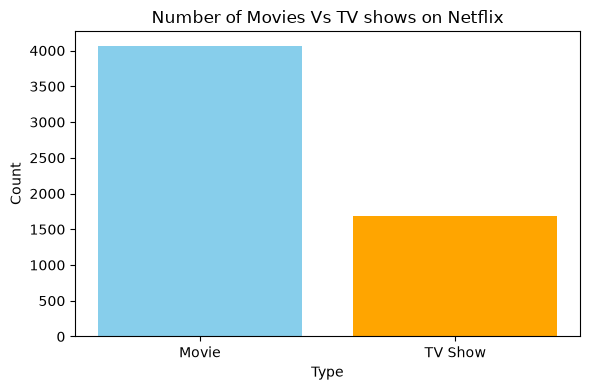

In [4]:
import pandas as pd 
import matplotlib.pyplot as plt


df = pd.read_csv("netflix_titles.csv")

# Clean Data 

df = df.dropna(subset=["type","release_year","rating","country","duration"])
type_counts = df["type"].value_counts()
plt.figure(figsize=(6,4))
plt.bar(type_counts.index,type_counts.values,color=["skyblue","orange"])

plt.title("Number of Movies Vs TV shows on Netflix")
plt.xlabel("Type")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("movie_Vs_tvshows.png")
plt.show()


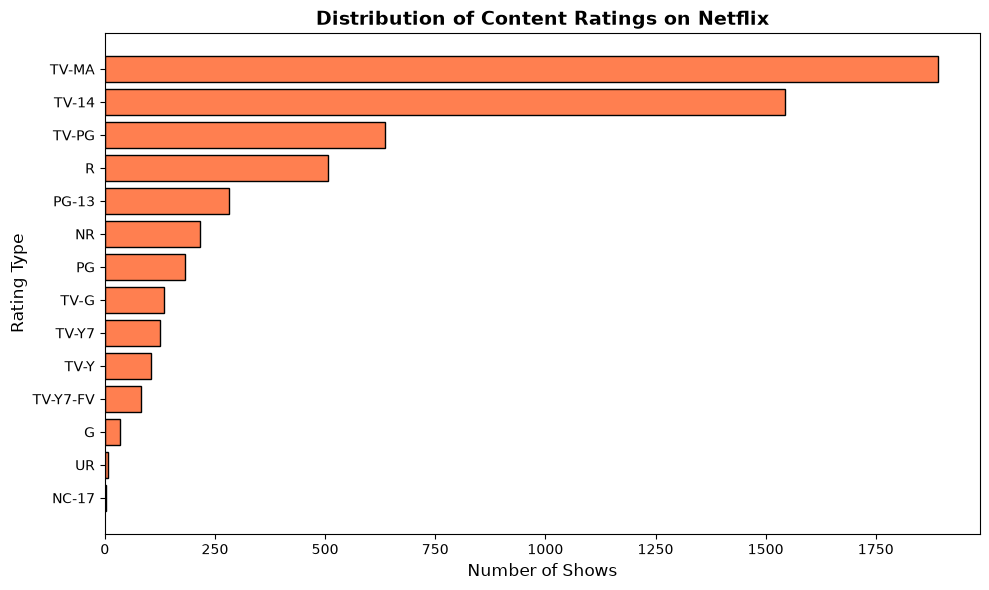

In [ ]:
# Content Rating counts 
rating_counts = df["rating"].value_counts()

plt.figure(figsize=(10, 6))
# Horizontal bar chart 
plt.barh(rating_counts.index, rating_counts.values, color="coral", edgecolor="black")

# Titles aur Labels
plt.title("Distribution of Content Ratings on Netflix", fontsize=14, fontweight='bold')
plt.xlabel("Number of Shows", fontsize=12)
plt.ylabel("Rating Type", fontsize=12)


plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig("Content_Rating_Clean.png")
plt.show()

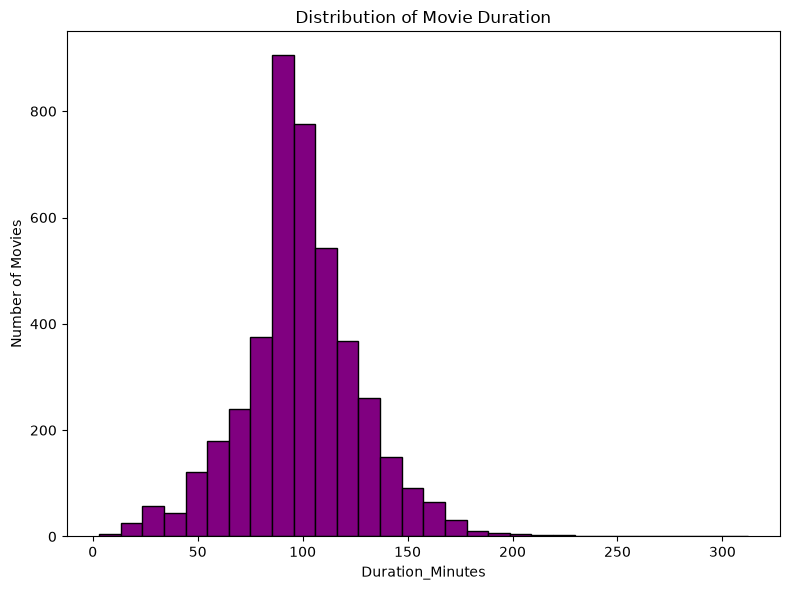

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt


df = pd.read_csv("netflix_titles.csv") 

movie_df = df[df["type"] == "Movie"].copy()
movie_df["duration_int"] = movie_df["duration"].str.replace(" min","").astype(int)
plt.figure(figsize=(8,6))
plt.hist(movie_df["duration_int"],bins=30,color="purple",edgecolor="black")
plt.title("Distribution of Movie Duration")

plt.xlabel("Duration_Minutes")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig("Movie_Duration.png")
plt.show()



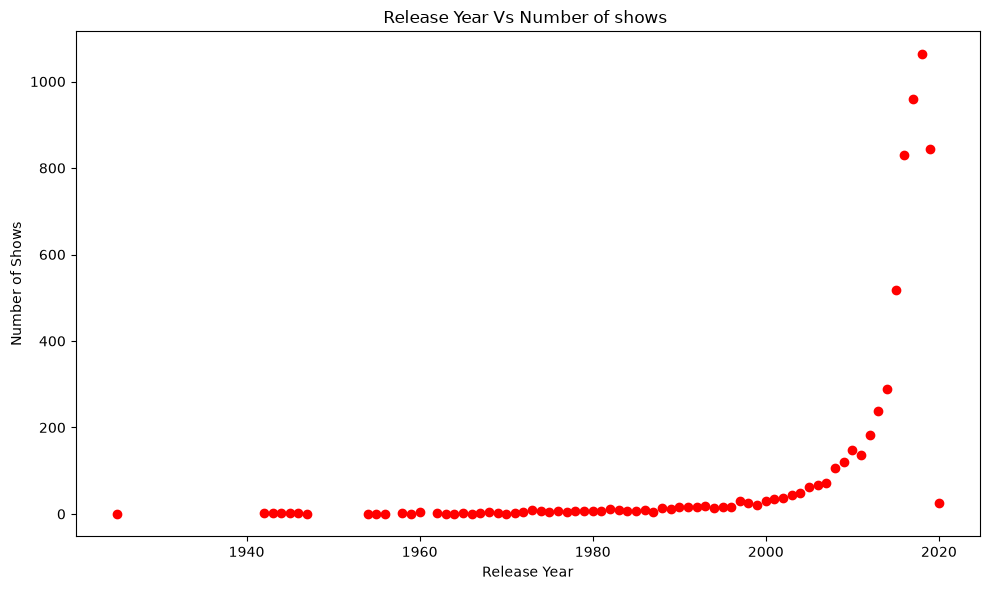

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt


df = pd.read_csv("netflix_titles.csv") 

release_counts= df["release_year"].value_counts().sort_index()
plt.figure(figsize=(10,6))
plt.scatter(release_counts.index,release_counts.values,color="red")

plt.title("Release Year Vs Number of shows ")
plt.xlabel("Release Year")
plt.ylabel("Number of Shows")
plt.tight_layout()
plt.savefig("Release_year_Scatter.png")
plt.show()

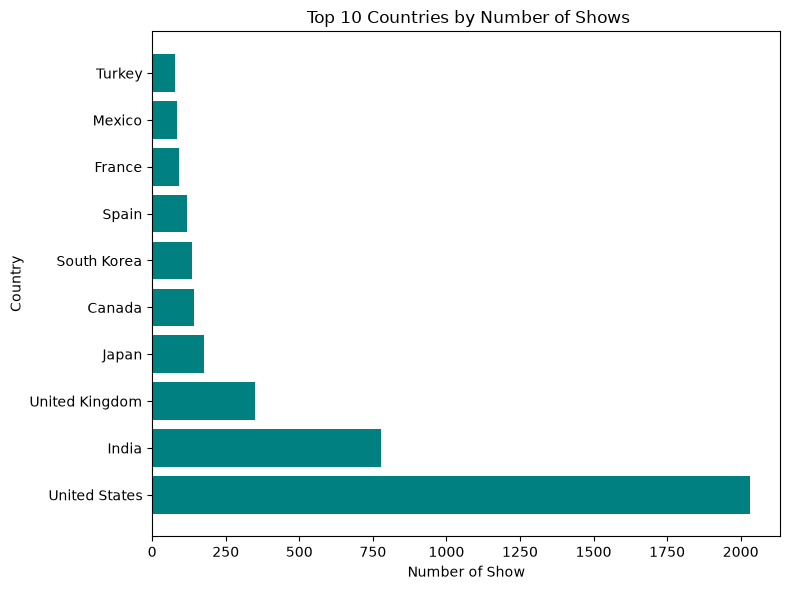

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt


df = pd.read_csv("netflix_titles.csv") 

country_counts = df["country"].value_counts().head(10)
plt.figure(figsize=(8,6))
plt.barh(country_counts.index,country_counts.values,color="teal")

plt.title(" Top 10 Countries by Number of Shows")
plt.xlabel("Number of Show")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("Top_10_Country.png")
plt.show()
plt.savefig('Country_Vs_Number_of_show.png')



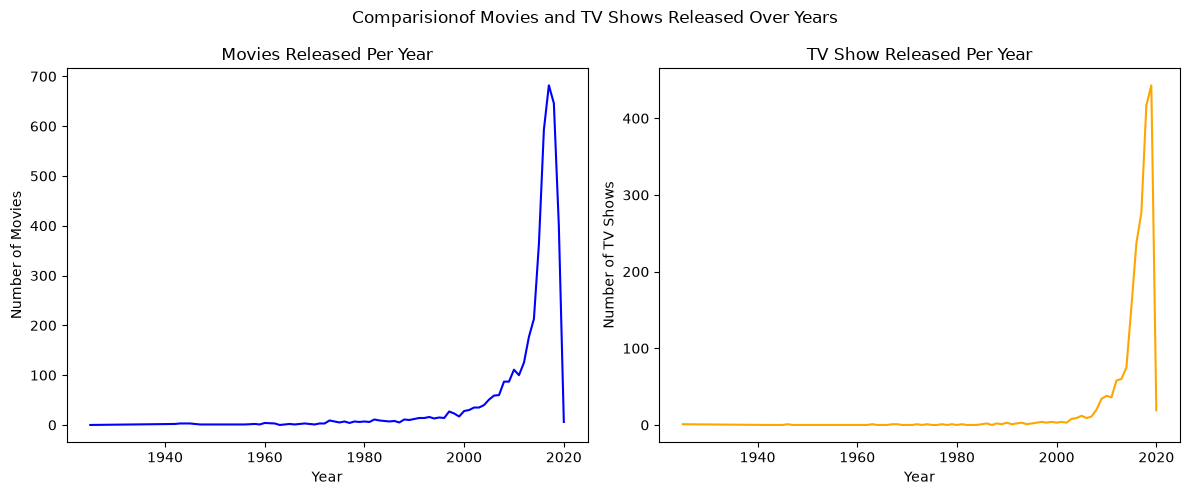

In [ ]:

import pandas as pd 
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_titles.csv") 
# Subplot.

content_by_year = df.groupby(["release_year","type"]).size().unstack().fillna(0)

fig,ax= plt.subplots(1,2,figsize=(12,5))

#First Subplot:Movies
# First Subplot: Movies
ax[0].plot(content_by_year.index, content_by_year["Movie"], color="blue")
ax[0].set_title("Movies Released Per Year")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Number of Movies")

# Second Subplot: TV Shows
ax[1].plot(content_by_year.index, content_by_year["TV Show"], color="orange")
ax[1].set_title("TV Show Released Per Year")
ax[1].set_xlabel("Year")
ax[1].set_ylabel("Number of TV Shows")

fig.suptitle("Comparisionof Movies and TV Shows Released Over Years")

plt.tight_layout()
plt.savefig('Movie_Tv_Shows_Comparsion.png')

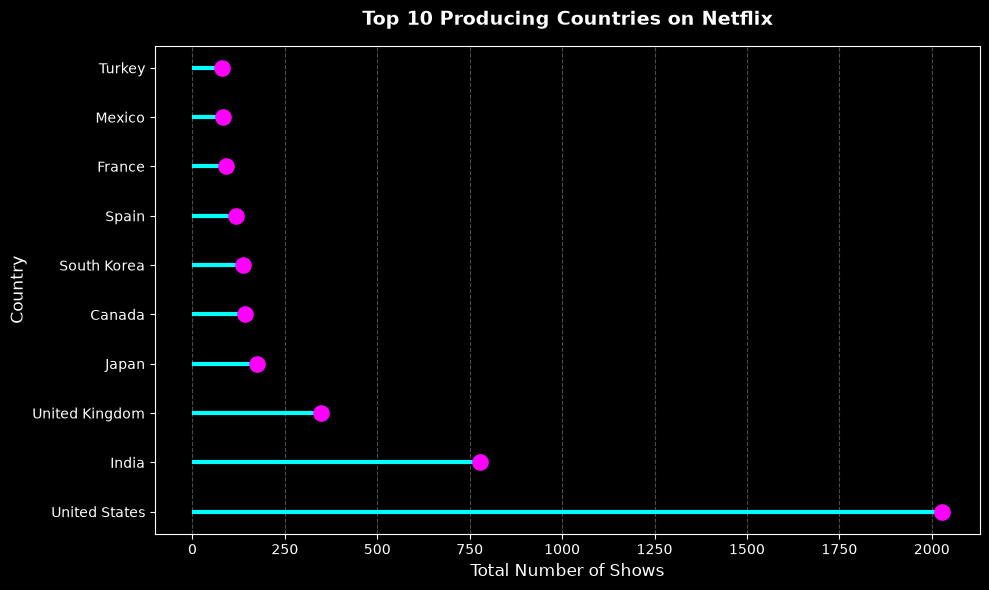

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('dark_background')

top_countries = df["country"].dropna().value_counts().head(10)


plt.figure(figsize=(10, 6))


plt.hlines(y=top_countries.index, xmin=0, xmax=top_countries.values, color='cyan', linewidth=3)

plt.scatter(top_countries.values, top_countries.index, color='magenta', s=120, zorder=3)

plt.title("Top 10 Producing Countries on Netflix", fontsize=14, fontweight='bold', color='white', pad=15)
plt.xlabel("Total Number of Shows", fontsize=12, color='white')
plt.ylabel("Country", fontsize=12, color='white')

plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig("Lollipop_Countries_Dark.png", dpi=300)
plt.show()

plt.style.use('default')